# Label-value oracle on ImageNet-C: does Ramen's cache help once its entries point toward their true labels?

**Question.** On DomainNet (`01_label_oracle_domainnet.ipynb`), giving each cache entry a cross-entropy
gradient toward its **true** label, instead of its own entropy gradient, raised accuracy by +1.70 points, while
filing entries by their true label *lowered* it under either value (−1.50 with entropy values, −0.25 with label
values). Does the same pattern hold on ImageNet-C? On ImageNet-C the filing-only oracle (`oracle_file_true`, 2026-10-23) was −0.71 points vs Ramen.

**Design: two factors, crossed** (all three oracles use true labels: **upper bounds, not methods**).

| | value = own entropy gradient (Ramen) | value = CE gradient toward the true label (ORACLE) |
|---|---|---|
| **filed by zero-shot prediction (Ramen)** | `Ramen` | `labeloracle_zs_ce` |
| **filed by true label (ORACLE)** | filing oracle | `labeloracle_true_ce` |

No image uses its own label: its entry holds its entropy gradient while its batch is adapted (as in Ramen), and
the label gradient replaces it only after the image has been predicted.

**Hypotheses (written before the runs, from DomainNet).**
- **H1.** Label values with Ramen's zero-shot filing beat Ramen by more than the noise floor.
- **H2.** True-label filing lowers accuracy under both values (filing oracle < Ramen, and
  `labeloracle_true_ce` < `labeloracle_zs_ce`).

**Data.** ImageNet-C (`ImageNetC5K`): 15 corruptions at severity 5, the same 5,000 ImageNet validation images under each (75,000 images), 1,000 classes; CLIP ViT-B/16; one mixed stream over all corruptions, batch size 100. Config `cfg/ImageNetC5K/Ramen.yaml`: queue capacity 75, top-k **1**, β **0** (each queue returns its single nearest entry, weighted e^(−H)), signSGD lr 0.01, fp16 priorities.

**Seeds.** Seed 0 only (screening); a seed sets the order of the stream. Noise floor = 2 × (max − min) of Ramen
over seeds 0–4.

**How the runs were produced.** Code in this folder only (`RamenLabelValues`, local registry; `src/` and `cfg/`
unchanged):
```
python run_label_oracle.py ImageNetC5K 0 --smoke smoke     # sanity check on 200 images per corruption (3,000)
python run_label_oracle.py ImageNetC5K 0 [--runs <name>]   # the new runs, one GPU each
```

**What counts as a result.** A change vs Ramen larger than the noise floor, in domain-averaged accuracy.

**Sections.** 1 Setup · 2 Data · 3 Sanity checks · 4 Results (2 × 2, per corruption, adapted-prediction
filing, global retrieval, copies hidden) · 5 Over-predicted classes · 6 Interpretation · 7 Glossary


## 1. Setup

In [1]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '')  # everything below reads cached runs

import pandas as pd
from IPython.display import display

from label_oracle import LABELS, SMOKE_CHECKS, SMOKE_RUNS, LabelOracleExperiment
from true_label_cache import count_pct, noise_floor, seed_table
import plots

pd.set_option('display.width', 220, 'display.max_columns', 20)
DATASET, BY = 'ImageNetC5K', 'domain'
exp = LabelOracleExperiment(DATASET, seed=0).run_all()
RUNS, ORACLES, FILING = list(exp.full_runs), list(exp.full_runs[2:]), exp.filing_oracle

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_NoAdapt.pkl
Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_Ramen.pkl


oracle_file_true: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_oracle_file_true.pkl
labeloracle_zs_ce: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_labeloracle_zs_ce.pkl
labeloracle_true_ce: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_labeloracle_true_ce.pkl


## 2. The data the code ran on

Images, classes and zero-shot correct counts: the denominators of everything below.

In [2]:
exp.data_table()

,images,classes,NoAdapt correct
domain,,,
gaussian_noise,5000,997,"750 of 5,000 (15.0%)"
shot_noise,5000,997,"844 of 5,000 (16.9%)"
impulse_noise,5000,997,"768 of 5,000 (15.4%)"
defocus_blur,5000,997,"1,284 of 5,000 (25.7%)"
glass_blur,5000,997,"845 of 5,000 (16.9%)"
motion_blur,5000,997,"1,341 of 5,000 (26.8%)"
zoom_blur,5000,997,"1,229 of 5,000 (24.6%)"
snow,5000,997,"1,700 of 5,000 (34.0%)"
frost,5000,997,"1,651 of 5,000 (33.0%)"


## 3. Sanity checks

### 3.1 The "off" settings reproduce their references exactly

On 200 images per corruption (3,000), `RamenLabelValues` with Ramen's value (entropy) must give the same predictions as Ramen (zero-shot filing) and as `RamenTrueLabel` (true-label filing): 100.00%.

In [3]:
smoke = LabelOracleExperiment(DATASET, seed=0, n_per_domain=200, results_dir='smoke').run_all(SMOKE_RUNS)
assert all(smoke.sanity_check(a, b) for a, b in SMOKE_CHECKS), 'off settings differ from their references'
smoke.summary_table(list(SMOKE_RUNS))

NoAdapt: loaded cached results from smoke/ImageNetC5K_clip_vitbase16_mixed_n200_bs100_s0_NoAdapt.pkl
Ramen: loaded cached results from smoke/ImageNetC5K_clip_vitbase16_mixed_n200_bs100_s0_Ramen.pkl
labeloracle_off: loaded cached results from smoke/ImageNetC5K_clip_vitbase16_mixed_n200_bs100_s0_labeloracle_off.pkl
RamenTrueLabel_true: loaded cached results from smoke/ImageNetC5K_clip_vitbase16_mixed_n200_bs100_s0_RamenTrueLabel_true.pkl
labeloracle_true_entropy: loaded cached results from smoke/ImageNetC5K_clip_vitbase16_mixed_n200_bs100_s0_labeloracle_true_entropy.pkl
labeloracle_zs_ce: loaded cached results from smoke/ImageNetC5K_clip_vitbase16_mixed_n200_bs100_s0_labeloracle_zs_ce.pkl
labeloracle_true_ce: loaded cached results from smoke/ImageNetC5K_clip_vitbase16_mixed_n200_bs100_s0_labeloracle_true_ce.pkl
late_zs_entropy: loaded cached results from smoke/ImageNetC5K_clip_vitbase16_mixed_n200_bs100_s0_late_zs_entropy.pkl
late_zs_ce: loaded cached results from smoke/ImageNetC5K_clip_

,correct,acc (domain avg),vs Ramen (pts),vs Ramen (images),fixed vs NoAdapt,broken vs NoAdapt,same pred as Ramen
NoAdapt,"813 of 3,000 (27.1%)",27.1,-3.83,-115,"0 of 3,000 (0.0%)","0 of 3,000 (0.0%)",54.63%
Ramen,"928 of 3,000 (30.9%)",30.93,+0.00,+0,"210 of 3,000 (7.0%)","95 of 3,000 (3.2%)",100.00%
labeloracle_off,"928 of 3,000 (30.9%)",30.93,+0.00,+0,"210 of 3,000 (7.0%)","95 of 3,000 (3.2%)",100.00%
RamenTrueLabel_true,"913 of 3,000 (30.4%)",30.43,-0.50,-15,"199 of 3,000 (6.6%)","99 of 3,000 (3.3%)",72.90%
labeloracle_true_entropy,"913 of 3,000 (30.4%)",30.43,-0.50,-15,"199 of 3,000 (6.6%)","99 of 3,000 (3.3%)",72.90%
labeloracle_zs_ce,"924 of 3,000 (30.8%)",30.8,-0.13,-4,"180 of 3,000 (6.0%)","69 of 3,000 (2.3%)",62.70%
labeloracle_true_ce,"870 of 3,000 (29.0%)",29.0,-1.93,-58,"149 of 3,000 (5.0%)","92 of 3,000 (3.1%)",60.73%
late_zs_entropy,"918 of 3,000 (30.6%)",30.6,-0.33,-10,"201 of 3,000 (6.7%)","96 of 3,000 (3.2%)",86.73%
late_zs_ce,"918 of 3,000 (30.6%)",30.6,-0.33,-10,"180 of 3,000 (6.0%)","75 of 3,000 (2.5%)",58.40%
late_adapted_entropy,"923 of 3,000 (30.8%)",30.77,-0.17,-5,"206 of 3,000 (6.9%)","96 of 3,000 (3.2%)",79.07%


### 3.2 The full runs

Same stream as Ramen; the labels the method saw agree with the scored labels (its count of zero-shot errors matches the zero-shot model's, up to fp16 near-ties); how many entries were ever stored and given a label value.

In [4]:
keys = ['domain_idx', 'sample_idx']
ram = exp.results['Ramen'][keys].to_numpy()
zs_wrong = int((~exp.results['NoAdapt']['correct']).sum())
rows = []
for n in exp.new_runs:
    st = exp.stats[n]
    row = {'run': n, 'same stream as Ramen': bool((exp.results[n][keys].to_numpy() == ram).all()),
           'zero-shot errors the method counted': f"{sum(st['zs_wrong']):,}",
           'zero-shot errors (NoAdapt)': f'{zs_wrong:,}'}
    if st['revealed']:
        row['entries given a label value'] = count_pct(sum(st['revealed']), len(ram))
    rows.append(row)
pd.DataFrame(rows).set_index('run')

,same stream as Ramen,zero-shot errors the method counted,zero-shot errors (NoAdapt),entries given a label value
run,,,,
labeloracle_zs_ce,True,"54,540","54,532","74,465 of 75,000 (99.3%)"
labeloracle_true_ce,True,"54,540","54,532","75,000 of 75,000 (100.0%)"


### 3.3 Noise floor

In [5]:
seeds = seed_table(DATASET, ('Ramen',))
floor = noise_floor(seeds['Ramen'])
print(f'Ramen over seeds 0-4: {seeds.Ramen.round(2).tolist()} -> noise floor {floor:.2f} points')

Ramen over seeds 0-4: [33.08, 33.17, 33.02, 32.91, 32.96] -> noise floor 0.53 points


## 4. Results

### 4.1 One row per run

Domain-averaged accuracy; counts are pooled over all images. Fixed / broken are relative to zero-shot.

In [6]:
exp.summary_table(RUNS)

,correct,acc (domain avg),vs Ramen (pts),vs Ramen (images),fixed vs NoAdapt,broken vs NoAdapt,same pred as Ramen
NoAdapt,"20,468 of 75,000 (27.3%)",27.29,-5.79,"-4,341","0 of 75,000 (0.0%)","0 of 75,000 (0.0%)",47.49%
Ramen,"24,809 of 75,000 (33.1%)",33.08,+0.00,+0,"7,205 of 75,000 (9.6%)","2,864 of 75,000 (3.8%)",100.00%
oracle_file_true,"24,276 of 75,000 (32.4%)",32.37,-0.71,-533,"6,520 of 75,000 (8.7%)","2,712 of 75,000 (3.6%)",71.24%
labeloracle_zs_ce,"25,938 of 75,000 (34.6%)",34.58,+1.51,"+1,129","7,837 of 75,000 (10.4%)","2,367 of 75,000 (3.2%)",67.41%
labeloracle_true_ce,"24,125 of 75,000 (32.2%)",32.17,-0.91,-684,"6,783 of 75,000 (9.0%)","3,126 of 75,000 (4.2%)",59.16%


### 4.2 The 2 × 2: filing × value

In [7]:
ft = exp.factor_table()
display(ft)
d = ft['vs Ramen (pts)']
value_effect = (d[('zero-shot', 'true-label CE')] + d[('true label', 'true-label CE')]
                - d[('zero-shot', 'entropy')] - d[('true label', 'entropy')]) / 2
filing_effect = (d[('true label', 'entropy')] + d[('true label', 'true-label CE')]
                 - d[('zero-shot', 'entropy')] - d[('zero-shot', 'true-label CE')]) / 2
print(f'main effect of label values: {value_effect:+.2f} pts; main effect of true-label filing: {filing_effect:+.2f} pts')

,,run,acc (domain avg),vs Ramen (pts),vs Ramen (images)
filing,value,,,,
zero-shot,entropy,Ramen,33.08,0.00,0
true label,entropy,oracle_file_true,32.37,-0.71,-533
zero-shot,true-label CE,labeloracle_zs_ce,34.58,1.51,1129
true label,true-label CE,labeloracle_true_ce,32.17,-0.91,-684


main effect of label values: +0.66 pts; main effect of true-label filing: -1.56 pts


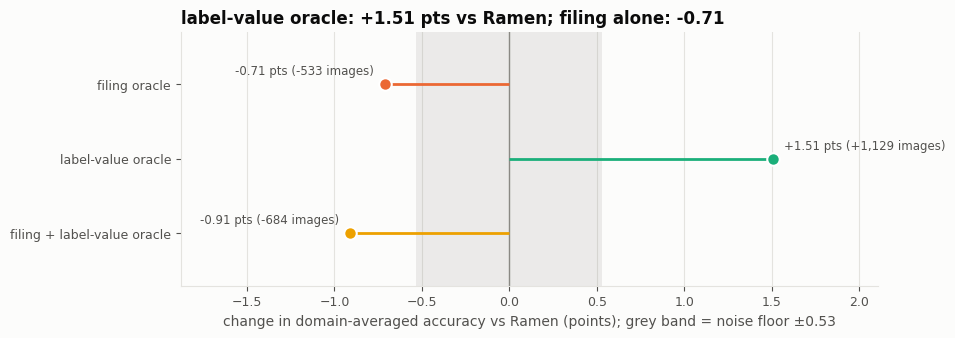

In [8]:
by_run = ft.reset_index().set_index('run')['vs Ramen (pts)']
best = by_run[ORACLES].idxmax()
title = f"{LABELS[best]}: {by_run[best]:+.2f} pts vs Ramen; filing alone: {by_run[FILING]:+.2f}"
plots.plot_vs_ramen(exp, ORACLES, floor, title=title);

### 4.3 Per corruption

In [9]:
exp.accuracy_table(RUNS, by=BY)

,NoAdapt,Ramen,oracle_file_true,labeloracle_zs_ce,labeloracle_true_ce
domain,,,,,
gaussian_noise,15.00,22.24,22.04,22.86,21.14
shot_noise,16.88,23.18,24.56,24.58,21.94
impulse_noise,15.36,23.64,22.02,24.32,22.58
defocus_blur,25.68,28.52,27.96,28.64,23.98
glass_blur,16.90,24.20,24.58,26.70,23.70
motion_blur,26.82,32.88,32.94,34.40,31.74
zoom_blur,24.58,29.76,29.02,31.48,28.96
snow,34.00,37.40,35.92,39.84,37.00
frost,33.02,34.98,32.32,38.02,36.18


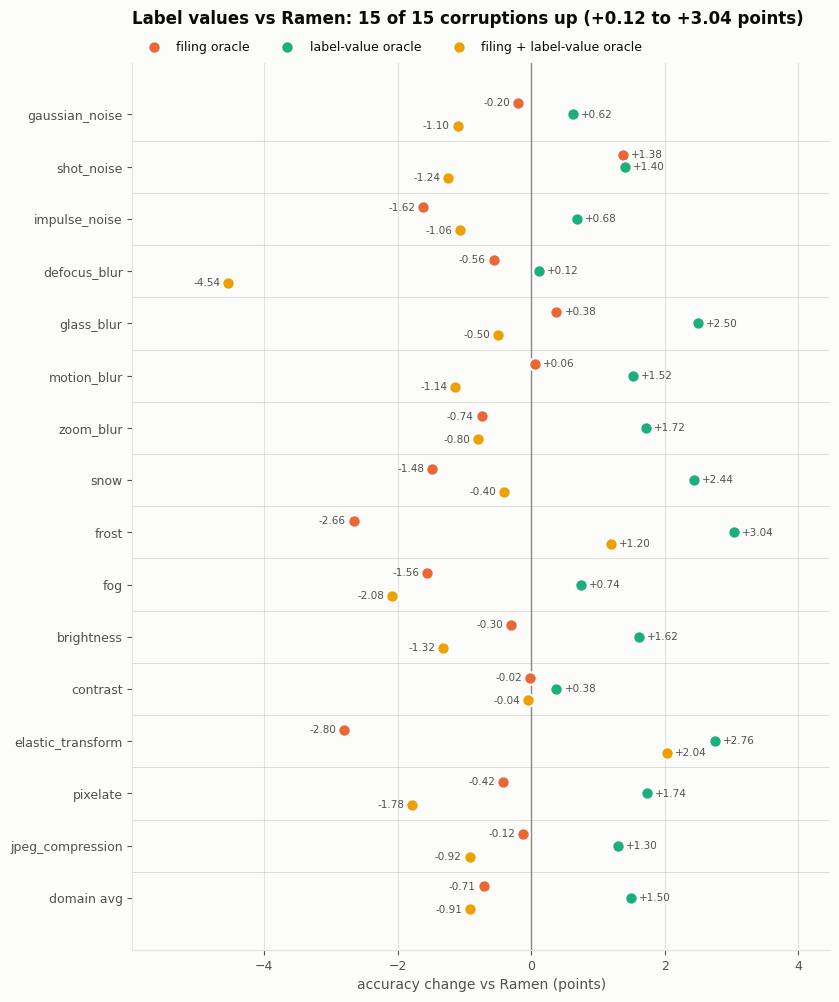

In [10]:
delta = exp.accuracy_table(ORACLES + ['Ramen'], by=BY).iloc[:-1]  # without the average row
gain = delta['labeloracle_zs_ce'] - delta['Ramen']
plots.plot_domain_change(exp, ORACLES, by=BY,
                         title=f"Label values vs Ramen: {(gain > 0).sum()} of {len(gain)} corruptions up "
                               f"({gain.min():+.2f} to {gain.max():+.2f} points)");

Fixed and broken images vs Ramen for the two label-value runs:

In [11]:
for n in ('labeloracle_zs_ce', 'labeloracle_true_ce'):
    print(LABELS[n])
    display(exp.change_table(n, baseline='Ramen', by=BY))

label-value oracle


,Ramen,labeloracle_zs_ce,images,fixed,broken,net (images),share of net gain
domain,,,,,,,
gaussian_noise,22.24,22.86,5000,170,139,31,2.7%
shot_noise,23.18,24.58,5000,212,142,70,6.2%
impulse_noise,23.64,24.32,5000,192,158,34,3.0%
defocus_blur,28.52,28.64,5000,262,256,6,0.5%
glass_blur,24.20,26.70,5000,319,194,125,11.1%
motion_blur,32.88,34.40,5000,303,227,76,6.7%
zoom_blur,29.76,31.48,5000,284,198,86,7.6%
snow,37.40,39.84,5000,300,178,122,10.8%
frost,34.98,38.02,5000,313,161,152,13.5%


filing + label-value oracle


,Ramen,labeloracle_true_ce,images,fixed,broken,net (images),share of net gain
domain,,,,,,,
gaussian_noise,22.24,21.14,5000,148,203,-55,8.0%
shot_noise,23.18,21.94,5000,168,230,-62,9.1%
impulse_noise,23.64,22.58,5000,165,218,-53,7.7%
defocus_blur,28.52,23.98,5000,220,447,-227,33.2%
glass_blur,24.20,23.70,5000,329,354,-25,3.7%
motion_blur,32.88,31.74,5000,255,312,-57,8.3%
zoom_blur,29.76,28.96,5000,259,299,-40,5.8%
snow,37.40,37.00,5000,257,277,-20,2.9%
frost,34.98,36.18,5000,361,301,60,-8.8%


### 4.4 A third filing rule: the adapted prediction

The Ramen paper (Sec. 3.2) and its code file each image under its **zero-shot** prediction. Filing under the
**adapted** prediction instead (Ramen's own output, more often right) needs the write moved *after* prediction,
because the adapted prediction exists only after retrieval and the step (`RamenWriteAfterPrediction`). That also
changes two things besides filing: an image no longer retrieves its own entry or later images of its batch, and
the first batch (empty cache) is predicted zero-shot. So each adapted run has a **timing control**: zero-shot
filing with the same late write.

| run | write | filing | value | uses labels? |
|---|---|---|---|---|
| `late_zs_entropy` | after prediction | zero-shot | entropy | no (timing control for Ramen) |
| `late_zs_ce` | after prediction | zero-shot | true-label CE | oracle (timing control) |
| `late_adapted_entropy` | after prediction | **adapted** | entropy | **no: a method** |
| `late_adapted_ce` | after prediction | **adapted** | true-label CE | oracle |

Checks (`check_write_after.py`, first 3,000 DomainNet images): the first batch is not adapted and equals zero-shot;
retrieval sees earlier batches only; every image is written to the queue of the class the method returned
(adapted filing) or its zero-shot class; 485 of 3,000 images are filed differently by the two rules.

In [12]:
from label_oracle import LATE_RUNS
exp.run_all(LATE_RUNS)
ft3 = exp.filing_table()
ft3

late_zs_entropy: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_late_zs_entropy.pkl
late_zs_ce: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_late_zs_ce.pkl
late_adapted_entropy: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_late_adapted_entropy.pkl
late_adapted_ce: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_late_adapted_ce.pkl


run  uses labels  acc (domain avg)  vs Ramen (pts)  vs Ramen (images)
write                    filing     value                                                                                                
before retrieval (Ramen) zero-shot  entropy                       Ramen        False             33.08            0.00                  0
                         true label entropy            oracle_file_true         True             32.37           -0.71               -533
                         zero-shot  true-label CE     labeloracle_zs_ce         True             34.58            1.51               1129
                         true label true-label CE   labeloracle_true_ce         True             32.17           -0.91               -684
after prediction         zero-shot  entropy             late_zs_entropy        False             32.91           -0.17               -124
                                    true-label CE            late_zs_ce         True             34.72            1.64               1233
                         adapted    entropy        late_adapted_entropy        False             33.20            0.12                 89
                                    true-label CE       late_adapted_ce         True             34.45            1.37               1031

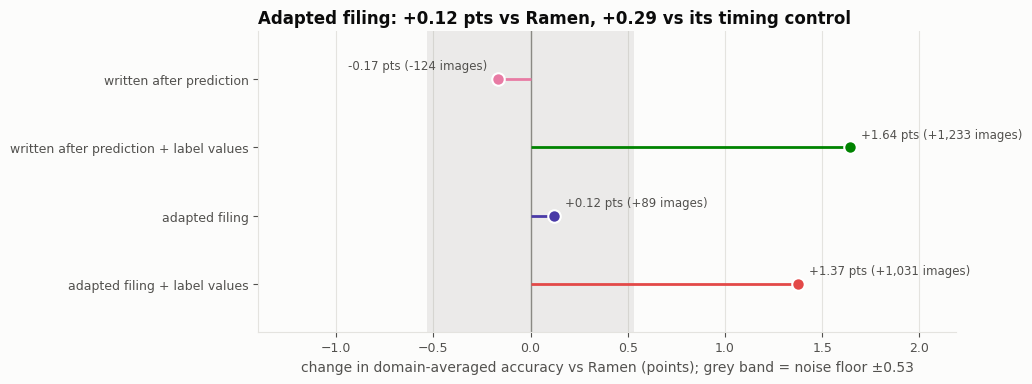

In [13]:
v = ft3.reset_index().set_index('run')['vs Ramen (pts)']
plots.plot_vs_ramen(exp, list(LATE_RUNS), floor,
                    title=f"Adapted filing: {v['late_adapted_entropy']:+.2f} pts vs Ramen, "
                          f"{v['late_adapted_entropy'] - v['late_zs_entropy']:+.2f} vs its timing control");

Per corruption: Ramen, its timing control, and adapted filing (both with entropy values).

In [14]:
late = exp.accuracy_table(['Ramen', 'late_zs_entropy', 'late_adapted_entropy'], by='domain')
late['adapted − timing control'] = late['late_adapted_entropy'] - late['late_zs_entropy']
late.round(2)

,Ramen,late_zs_entropy,late_adapted_entropy,adapted − timing control
domain,,,,
gaussian_noise,22.24,22.10,23.28,1.18
shot_noise,23.18,23.00,24.60,1.60
impulse_noise,23.64,23.54,22.76,-0.78
defocus_blur,28.52,28.18,28.86,0.68
glass_blur,24.20,24.18,24.38,0.20
motion_blur,32.88,32.74,33.36,0.62
zoom_blur,29.76,29.80,29.82,0.02
snow,37.40,36.98,37.18,0.20
frost,34.98,34.54,35.26,0.72


### 4.5 Global top-k retrieval: is the queue-averaged vote the bottleneck?

Ramen takes the top-k entries of **every** non-empty class queue and averages them, so most of an update comes
from classes the image is not. `RamenGlobalRetrieval` with `retrieval: global_knn` keeps everything else (filing,
values, timing, weights e^(−H)·e^(−β·d)) and instead takes the **k nearest entries of the whole cache**, normalised
by their total weight.

| run | retrieval | value | uses labels? |
|---|---|---|---|
| `labeloracle_zs_ce` | top-k per queue (Ramen) | true-label CE | oracle |
| `global_ce_k10`, `global_ce_k100`, `global_ce_k1000` | k nearest overall | true-label CE | oracle |
| `global_entropy_k100` | 100 nearest overall | entropy | **no: a method** |

Check: with `retrieval: per_class` (`global_off`) the class reproduces Ramen on every smoke image (section 3.1).

**On ImageNet-C these numbers carry a label leak** (other corrupted copies of the same photo); section 4.6 removes it.

In [15]:
from label_oracle import GLOBAL_RUNS
exp.run_all(GLOBAL_RUNS)
gt = exp.vs_table(['labeloracle_zs_ce', *GLOBAL_RUNS], baselines=('Ramen', 'labeloracle_zs_ce'))
gt

global_ce_k10: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_global_ce_k10.pkl
global_ce_k100: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_global_ce_k100.pkl
global_ce_k1000: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_global_ce_k1000.pkl
global_entropy_k100: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_global_entropy_k100.pkl


,label,acc (domain avg),vs Ramen (pts),vs Ramen (images),vs labeloracle_zs_ce (pts),vs labeloracle_zs_ce (images)
run,,,,,,
labeloracle_zs_ce,label-value oracle,34.58,1.51,1129,0.00,0
global_ce_k10,global k=10 + label values,37.05,3.97,2979,2.47,1850
global_ce_k100,global k=100 + label values,36.90,3.82,2866,2.32,1737
global_ce_k1000,global k=1000 + label values,35.88,2.80,2101,1.30,972
global_entropy_k100,global k=100 (no labels),32.22,-0.86,-647,-2.37,-1776


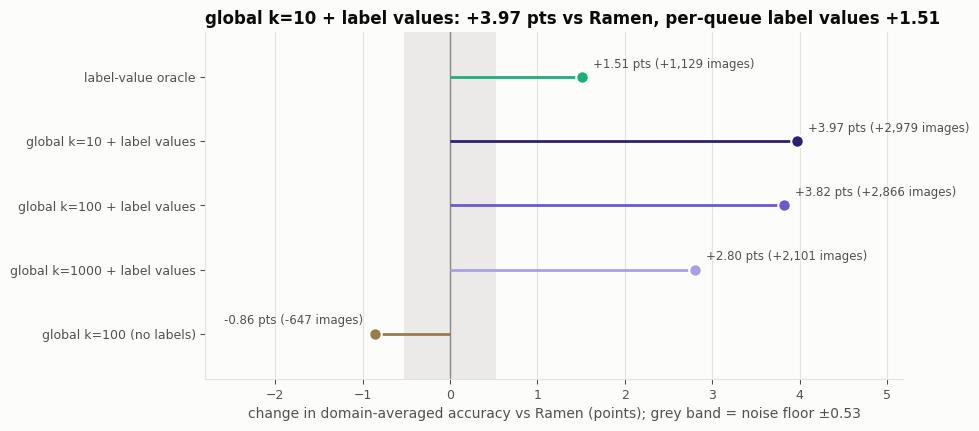

In [16]:
g = gt['vs Ramen (pts)']
best = g[list(GLOBAL_RUNS)].idxmax()
plots.plot_vs_ramen(exp, ['labeloracle_zs_ce', *GLOBAL_RUNS], floor,
                    title=f"{LABELS[best]}: {g[best]:+.2f} pts vs Ramen, per-queue label values "
                          f"{g['labeloracle_zs_ce']:+.2f}");

Per corruption:

In [17]:
gacc = exp.accuracy_table(['Ramen', 'labeloracle_zs_ce', *GLOBAL_RUNS], by='domain')
gacc.round(2)

,Ramen,labeloracle_zs_ce,global_ce_k10,global_ce_k100,global_ce_k1000,global_entropy_k100
domain,,,,,,
gaussian_noise,22.24,22.86,27.76,23.96,21.64,20.64
shot_noise,23.18,24.58,28.22,25.18,23.70,22.12
impulse_noise,23.64,24.32,26.30,24.26,23.62,20.98
defocus_blur,28.52,28.64,32.88,31.78,29.84,29.40
glass_blur,24.20,26.70,28.72,28.94,28.96,23.68
motion_blur,32.88,34.40,36.02,35.54,35.52,32.44
zoom_blur,29.76,31.48,34.50,34.40,33.56,28.76
snow,37.40,39.84,44.04,44.26,41.78,37.54
frost,34.98,38.02,42.72,42.10,40.48,34.94


### 4.6 Hiding the other copies of each photo (ImageNet-C only)

`ImageNetC5K` uses the **same 5,000 photos** under all 15 corruptions, so the stream holds 15 copies of every
photo. With label values, an entry made from another corruption of the query's photo carries the query's own
label: a leak that per-class retrieval barely touches (one entry per queue) but global retrieval can (the nearest
entries are often other copies). The `excl_` runs hide from retrieval every entry whose photo is the query's,
except the query's own entry (whose value is still its entropy gradient when it is predicted). `excl_zs_entropy`
is Ramen with copies hidden, the baseline for this section.

Checks (`check_exclusion.py`, first 200 batches): no retrieved entry is another copy (X1 = 0); without exclusion,
other copies carry 0.0% of the update with per-class top-1 but 4.0% with global top-10 (X2). On the smoke subset
the exclusion code path with nothing hidden matches Ramen on 2,988 of 3,000 images (its distances are fp32).

In [18]:
print(''.join(l for l in open('logs/check_exclusion_ImageNetC5K.log') if l.startswith(('===', 'X'))))

=== excl_zs_ce (retrieval per_class, k 1), first 200 batches
X1  retrieved entries that are another copy of the query's photo: 0 (must be 0)
X2  without exclusion, mean share of the update on other copies: per-class top-1 0.0% (second half of the traced batches 0.1%); global top-100 1.3% (second half 1.7%)
=== excl_global_ce_k10 (retrieval global_knn, k 10), first 200 batches
X1  retrieved entries that are another copy of the query's photo: 0 (must be 0)
X2  without exclusion, mean share of the update on other copies: per-class top-1 0.0% (second half of the traced batches 0.1%); global top-10 4.0% (second half 5.3%)



In [19]:
from label_oracle import EXCL_RUNS
exp.run_all(EXCL_RUNS)
pairs = {'labeloracle_zs_ce': 'excl_zs_ce', **{n: f'excl_{n}' for n in GLOBAL_RUNS}}
v = exp.vs_table([*pairs, *pairs.values(), 'excl_zs_entropy'], baselines=('Ramen', 'excl_zs_entropy'))
leak = pd.DataFrame({'copies visible: vs Ramen (pts)': v.loc[list(pairs), 'vs Ramen (pts)'].to_numpy(),
                     'copies hidden: vs Ramen with copies hidden (pts)':
                         v.loc[list(pairs.values()), 'vs excl_zs_entropy (pts)'].to_numpy(),
                     'copies hidden (images)': v.loc[list(pairs.values()), 'vs excl_zs_entropy (images)'].to_numpy()},
                    index=[LABELS[n] for n in pairs])
print(f"Ramen with copies hidden vs Ramen: {v.loc['excl_zs_entropy', 'vs Ramen (pts)']:+.2f} pts")
leak

excl_zs_entropy: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_excl_zs_entropy.pkl
excl_zs_ce: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_excl_zs_ce.pkl
excl_global_ce_k10: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_excl_global_ce_k10.pkl
excl_global_ce_k100: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_excl_global_ce_k100.pkl
excl_global_ce_k1000: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_excl_global_ce_k1000.pkl
excl_global_entropy_k100: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_excl_gl

,copies visible: vs Ramen (pts),copies hidden: vs Ramen with copies hidden (pts),copies hidden (images)
label-value oracle,1.51,0.92,693
global k=10 + label values,3.97,-1.00,-750
global k=100 + label values,3.82,0.18,136
global k=1000 + label values,2.80,0.95,709
global k=100 (no labels),-0.86,-1.57,-1181


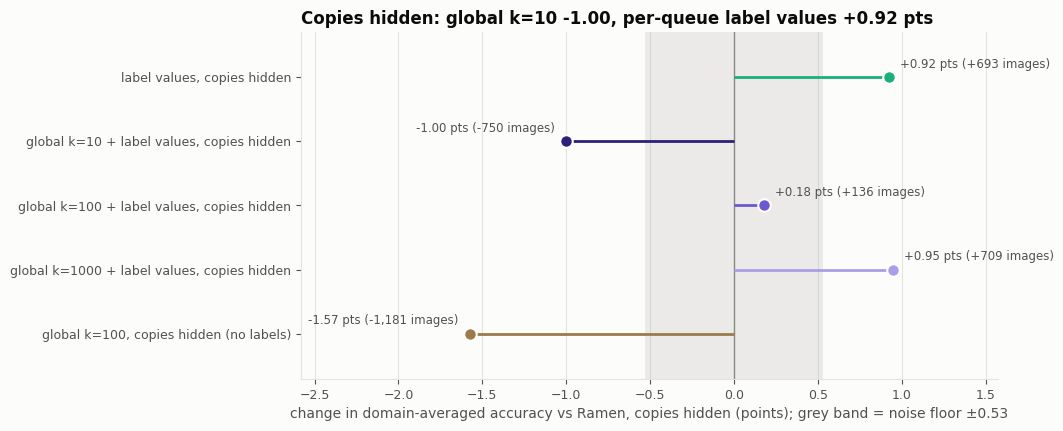

In [20]:
h = v['vs excl_zs_entropy (pts)']
plots.plot_vs_ramen(exp, list(pairs.values()), floor, baseline='excl_zs_entropy',
                    title=f"Copies hidden: global k=10 {h['excl_global_ce_k10']:+.2f}, per-queue label values "
                          f"{h['excl_zs_ce']:+.2f} pts");

## 5. Over-predicted classes

The classes Ramen predicts wrongly most often, and how often each run predicts them wrongly (a sink is a class predicted for many images of other classes).

In [21]:
exp.top_sinks(10)

,truly this class,zero-shot,Ramen,filing oracle,label-value oracle,filing + label-value oracle
class (wrong predictions),,,,,,
window screen,45,940,489,1509,576,265
rock crab,90,69,271,127,290,268
Brittany dog,105,461,266,297,222,328
CRT monitor,45,3202,261,1887,339,354
rain barrel,75,140,250,304,185,143
mosquito net,45,67,216,259,88,40
dishcloth,60,276,196,218,194,154
jacamar,90,230,187,193,194,171
feather boa,60,251,183,180,88,34


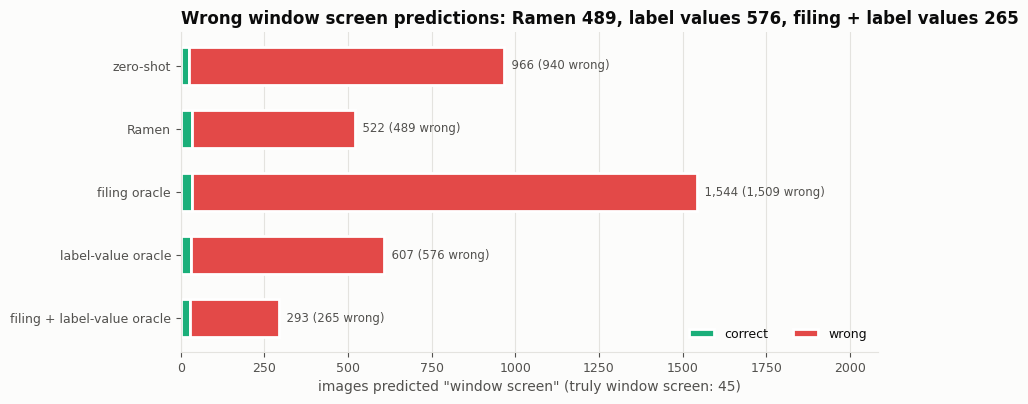

In [22]:
sink = exp.top_sinks(1).index[0]
wrong = exp.top_sinks(1).iloc[0]
plots.plot_class_predictions(exp, sink, RUNS,
                             title=f"Wrong {sink} predictions: Ramen {wrong['Ramen']:,}, label values "
                                   f"{wrong[LABELS['labeloracle_zs_ce']]:,}, filing + label values "
                                   f"{wrong[LABELS['labeloracle_true_ce']]:,}");

## 6. Interpretation

**What the numbers say (seed 0; noise floor 0.53 points).**

| | entropy values (Ramen) | true-label CE values (ORACLE) |
|---|---|---|
| **zero-shot filing (Ramen)** | 33.08 | **34.58 (+1.51, +1,129 images)** |
| **true-label filing (ORACLE)** | 32.37 (−0.71) | 32.17 (−0.91, −684 images) |
| **adapted filing, written after prediction** | 33.20 (+0.12) | 34.45 (+1.37) |
| **zero-shot filing, written after prediction (timing control)** | 32.91 (−0.17) | 34.72 (+1.64) |

- **H1 holds.** Label values with Ramen's filing beat Ramen by +1.51 points, about 3 × the noise floor, and
  raise all 15 corruptions (from +0.12 on defocus blur to +3.04 on frost). Part of this is a leak (other corrupted copies
  of the same photo carry its label, section 4.6): with those hidden the gain is **+0.92**, still above the floor.
  The other label-value runs in this table carry the same leak.
- **H2 holds.** True-label filing lowers accuracy under both values: −0.71 with entropy values, and −0.91
  against +1.51 with label values. With labels in the values, true-label filing costs 2.42 points.
- **Adapted filing is not a gain.** +0.12 vs Ramen and +0.29 vs its timing control, both below the floor. It
  helps some corruptions (shot noise +1.60, gaussian noise +1.18) and hurts others (elastic −1.06, impulse
  −0.78).
- **The same pattern as DomainNet, with a flatter vote.** ImageNet-C's config takes the single nearest entry
  from each of 1,000 queues (top-k 1, β 0), so an update is an entropy-weighted average over up to 1,000
  entries, one per class.

**Global retrieval (sections 4.5–4.6): its gain here was a leak.**

| run | copies visible, vs Ramen | copies hidden, vs Ramen with copies hidden |
|---|---|---|
| per-queue label values | +1.51 | **+0.92 (+693 images)** |
| global k=10 + label values | +3.97 | −1.00 (−750) |
| global k=100 + label values | +3.82 | +0.18 (+136) |
| global k=1000 + label values | +2.80 | +0.95 (+709) |
| global k=100, no labels | −0.86 | −1.57 (−1,181) |

- With the copies visible, global top-10 looked like +3.97. The stream holds 15 corrupted copies of each photo,
  and with label values a copy carries the query's own label. Copies are only 4.0% of a global top-10 update
  (`check_exclusion.py`), but they all point the same, right way, while the rest of the update is spread over
  many classes.
- With the copies hidden, label values still help per queue (+0.92, above the 0.53 floor), but **global retrieval
  adds nothing**: k=1000 is level with per-queue (+0.95), and k=10 is worse than Ramen (−1.00). Hiding the copies
  costs Ramen itself nothing (−0.05).
- Global retrieval without labels hurts (−0.86, or −1.57 with copies hidden).

**What it does not show.** One seed; the oracles are upper bounds, not methods. No cache replay was run here
(it needs recorded zero-shot features), so the vote-share mechanism is DomainNet's, not measured on ImageNet-C.


## 7. Glossary

| term | meaning |
|---|---|
| zero-shot | CLIP classifies by cosine similarity between the image embedding and each class's text embedding. No adaptation. |
| Ramen | test-time adaptation. Each image is written into a class queue with its own gradient; the gradients of the nearest stored entries are retrieved (top-k per non-empty queue, weighted e^(−H)·e^(−β·d), queues averaged), one signSGD step is taken on the image encoder's LayerNorm parameters, the image is predicted, and the parameters are reset. |
| filing | which queue an image is written to: its zero-shot prediction (Ramen, as in the paper and its code), its true label (oracle), or its adapted prediction (written after prediction). |
| timing control | zero-shot filing with the write moved after prediction: isolates the timing change that adapted filing needs. |
| value | the gradient an entry stores: the image's own entropy gradient (Ramen; sharpens the zero-shot prediction) or the cross-entropy gradient toward its true label (label oracle), stored once the image has been predicted. |
| filing oracle | filed by true label, Ramen's entropy values (`oracle_file_true` or `labeloracle_true_entropy`). |
| label-value oracle | `labeloracle_zs_ce`: filed by zero-shot prediction, label values. |
| filing + label-value oracle | `labeloracle_true_ce`: both. |
| oracle | a run that uses ground-truth labels: an upper bound, not a method. |
| main effect | the change from switching one factor, averaged over the two settings of the other factor. |
| noise floor | 2 × (max − min) of Ramen's domain-averaged accuracy over seeds 0–4; a change must exceed it to count. |
| fixed / broken | images a run gets right that the baseline got wrong / wrong that the baseline got right. |
| domain average | the mean of the per-domain (here per-corruption) accuracies; pooled accuracy for a one-domain dataset. |
| global top-k retrieval | the k nearest entries of the whole cache, whatever their queue (`RamenGlobalRetrieval`, `retrieval: global_knn`), instead of Ramen's top-k of every queue. |
| copies hidden | ImageNet-C only: entries made from another corruption of the query's photo are left out of retrieval (`exclude_groups`); with label values they would carry the query's label. |
